# Financial Health Prediction

##Install Packages

## Import  packages

In [1]:
!pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
fh_df = pd.read_csv(r'C:\Users\USER\Documents\Financail_health\Rawdata\financial_health.csv')

In [4]:
fh_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9618 entries, 0 to 9617
Data columns (total 39 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   ID                                                                9618 non-null   str    
 1   country                                                           9618 non-null   str    
 2   owner_age                                                         9618 non-null   float64
 3   attitude_stable_business_environment                              9616 non-null   str    
 4   attitude_worried_shutdown                                         9616 non-null   str    
 5   compliance_income_tax                                             9614 non-null   str    
 6   perception_insurance_doesnt_cover_losses                          9613 non-null   str    
 7   perception_cannot_afford_insurance          

In [5]:
def basic_eda (data):
    print("="*45)
    print("financial data overview")
    print("="*45)


    #First 5 rows
    print("Fist 5 rows:\n", fh_df.head(5))
    print("="*45)

    # Count Missing Values
    print("Total Missing Values:\n",fh_df.isnull().sum())
    print("="*45)

    # Count exact duplicate rows
    print("Number of Duplicates:\n",fh_df.duplicated().sum())
    print("="*45)

    #Target Column
    y = fh_df['Target']



In [6]:
def basic_checks(df):
    '''Perform basics checks i.e null summary, duplicates, summary statistics etc
    '''
    # Check for missing values.  
    print('-'*40,"Misssing values",'-'*40)
    print(df.isnull().sum())

    # Duplicates check
    print('-'*40,"Duplicates check",'-'*40)
    print(df.duplicated().sum())

    # Check for the data types
    print('-'*40,"Summary info.",'-'*40)
    print(df.info())

    # Summary Statistics
    # Numeric
    print(display(df.describe().T))

    # Categorical
    print(display(df.describe(include='str').T))

    # Shape of the dataset
    print('-'*40,"Shape of the dataset",'-'*40)
    print(df.shape)

In [7]:
pd.set_option("display.max_colwidth", None)

In [8]:
fh_df.head()


,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,Never had,Never had,NaN,6.0,Never had,Used to have but don’t have now,NaN,Never had,Never had,Low
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,3.0,Never had,Never had,NaN,NaN,NaN,Medium
2,ID_TY93LV,malawi,34.0,Don’t know or N/A,No,No,Don't know,Yes,30000.0,6000.0,...,Never had,Never had,Yes,NaN,NaN,NaN,Yes,NaN,NaN,Low
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,Never had,Never had,No,NaN,NaN,NaN,Yes,Never had,Have now,Low
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,0.0,Never had,Never had,Yes,NaN,NaN,Low


In [9]:
fh_df


,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,Never had,Never had,NaN,6.0,Never had,Used to have but don’t have now,NaN,Never had,Never had,Low
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,3.0,Never had,Never had,NaN,NaN,NaN,Medium
2,ID_TY93LV,malawi,34.0,Don’t know or N/A,No,No,Don't know,Yes,30000.0,6000.0,...,Never had,Never had,Yes,NaN,NaN,NaN,Yes,NaN,NaN,Low
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,Never had,Never had,No,NaN,NaN,NaN,Yes,Never had,Have now,Low
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,0.0,Never had,Never had,Yes,NaN,NaN,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9613,ID_D7NC2D,lesotho,31.0,Yes,No,No,Don't know,Don't know,2000.0,800.0,...,NaN,NaN,NaN,NaN,NaN,NaN,No,Have now,Never had,Medium
9614,ID_NT06RL,malawi,64.0,Don’t know or N/A,Don’t know or N/A,Yes,No,No,10000000.0,5000000.0,...,Never had,Have now,Yes,NaN,NaN,NaN,No,NaN,NaN,High
9615,ID_4TVWA3,zimbabwe,43.0,Yes,No,No,Yes,No,450.0,NaN,...,NaN,NaN,No,8.0,Have now,Have now,NaN,NaN,NaN,Medium
9616,ID_3U3S2Z,zimbabwe,38.0,Yes,Yes,No,No,Yes,2000.0,NaN,...,NaN,NaN,No,0.0,Never had,Never had,NaN,NaN,NaN,Low


In [10]:
basic_checks(fh_df)

---------------------------------------- Misssing values ----------------------------------------
ID                                                                     0
country                                                                0
owner_age                                                              0
attitude_stable_business_environment                                   2
attitude_worried_shutdown                                              2
compliance_income_tax                                                  4
perception_insurance_doesnt_cover_losses                               5
perception_cannot_afford_insurance                                     5
personal_income                                                      109
business_expenses                                                    229
business_turnover                                                    216
business_age_years                                                   252
motor_vehicle_insurance   

,count,mean,std,min,25%,50%,75%,max
owner_age,9618.0,4.170534e+01,1.331401e+01,18.0,32.0,40.0,50.0,103.0
personal_income,9509.0,2.627345e+05,2.566268e+06,0.0,300.0,2000.0,25000.0,150000000.0
business_expenses,9389.0,4.583838e+05,6.184746e+06,0.0,700.0,3000.0,25000.0,500000000.0
business_turnover,9402.0,1.348210e+06,8.804741e+06,0.0,1500.0,6000.0,50000.0,420000000.0
business_age_years,9366.0,7.030536e+00,7.650349e+00,0.0,2.0,4.0,10.0,60.0
business_age_months,5507.0,3.636281e+00,3.386488e+00,0.0,0.0,3.0,6.0,11.0


None


,count,unique,top,freq
ID,9618,9618,ID_3CFL0U,1
country,9618,4,eswatini,2674
attitude_stable_business_environment,9616,3,Yes,5820
attitude_worried_shutdown,9616,3,No,5804
compliance_income_tax,9614,4,No,8010
perception_insurance_doesnt_cover_losses,9613,3,No,4486
perception_cannot_afford_insurance,9613,3,Yes,6056
motor_vehicle_insurance,7374,4,Never had,6994
has_mobile_money,6867,5,Have now,4876
current_problem_cash_flow,5840,3,Yes,2688


None
---------------------------------------- Shape of the dataset ----------------------------------------
(9618, 39)


In [11]:
pd.set_option("display.max_columns", None)

In [12]:
def basic_check(df):
    print("Duplicates: \n", df.duplicated().sum())
    print(64 * "#")
    print("Columns; \n", df.columns)
    print(64 * "#")
    print("Shape: \n", df.shape)
    print(64 * "#")
    print("Checking missing values \n", df.isna().sum())
    print(64 * "#")
    print("Checking the datatypes: \n", df.info())
    print(64 * "#")
    print(display("Numerical summary statistics: \n", df.describe().T))
    print(64 * "#")
    print(display("Categorical summary statistics: \n", df.describe(include=['str', 'object']).T))

In [13]:
def basics_check(df):
    print("Duplicates: ",df.duplicated().sum())
    print(64 *"#")
    print("Columns: ",df.columns)
    print(64 *"#")
    print("Shape: ",df.shape)
    print(64 *"#")
    print("Checking missing values: ",df.isna().sum())
    print(64 *"#")
    print("checking datatypes: ",df.info())
    print(64 *"#")
    print("Numerical summary statistiics: ",display(df.describe().T))
    print(64 *"#")
    print("Categorical summary statistiics: ",display(df.describe(include =["object","str"]).T))

In [14]:
def basic_checks(df):
    print('Duplicate: \n', df.duplicated().sum())

    print('Missing Values: \n', df.isnull().sum())

    print('Shape: \n', df.shape)

    print('Columns: \n', df.columns)

    print('Data types: \n', df.info())

    print(display('Categorical Summary Statistics: \n', df.describe(include=['str','object']).T))
    

#### Categorical Entries

In [15]:
categorical_columns = fh_df.select_dtypes(include=('object')).columns.to_list()

print(categorical_columns)

for col in categorical_columns:
    print("-"*35, col.upper(), "-"*35)
    print(fh_df[col].unique())
    print(fh_df[col].nunique())

['ID', 'country', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_informal_lender', 'Target']
----------------------------------- ID -----------------------------------
<StringArray>
['ID_3CFL0U', 'ID_XWI7G3', 'ID_TY

['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'business_age_months']


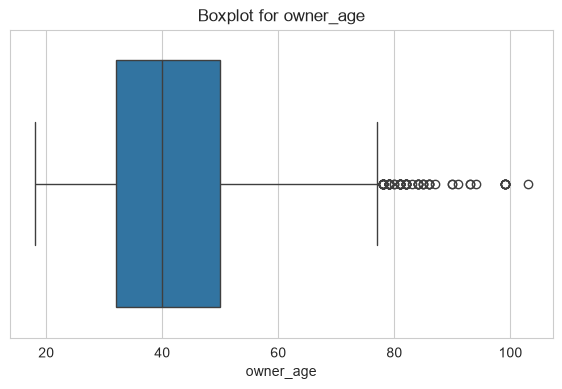

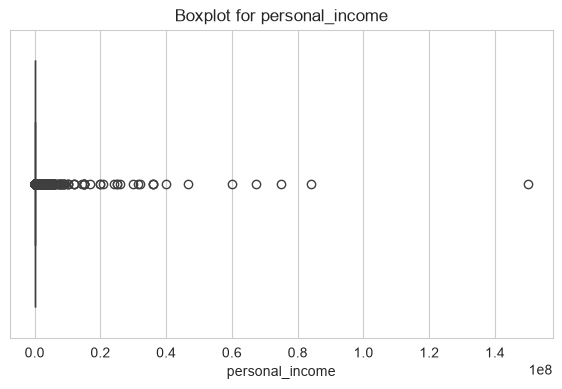

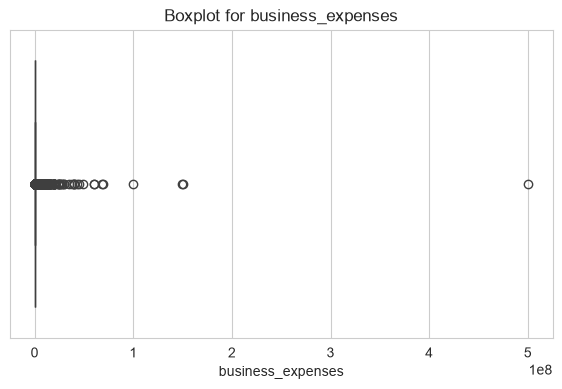

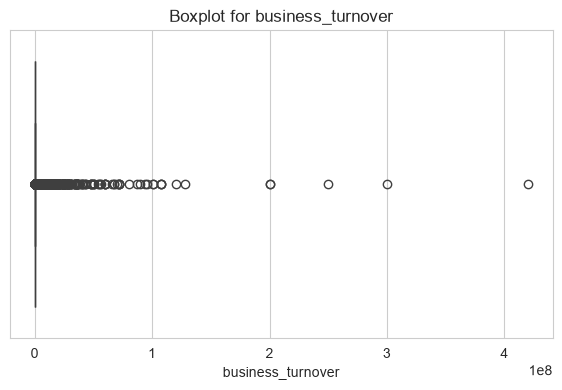

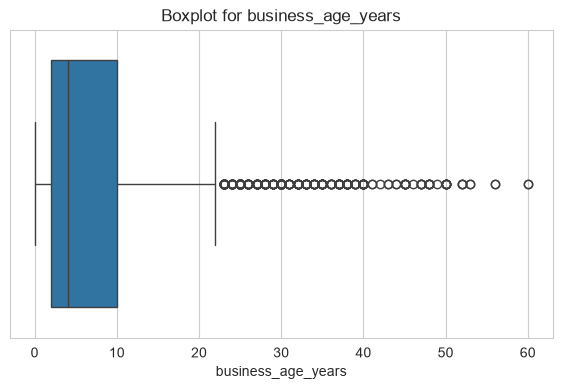

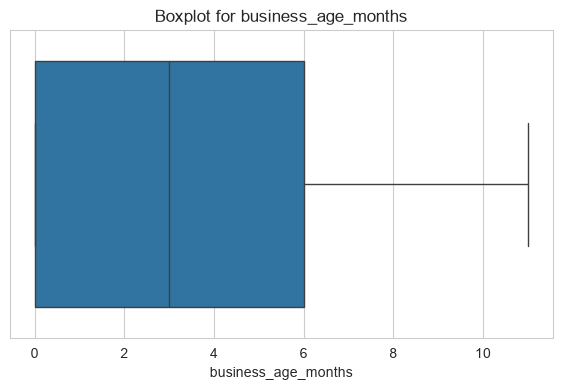

In [16]:
num_cols = fh_df.select_dtypes(include=('int', 'float')).columns.to_list()

print(num_cols)

for col in num_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=fh_df, x=col)
    plt.title(f"Boxplot for {col}")
    plt.xlabel(col)
    plt.ylabel("")
    plt.show()

## Step 3: Data Cleaning

In [17]:
fh_df.drop_duplicates(inplace=True)

#Check if dropped
fh_df.duplicated().sum()

np.int64(0)